# Seaborn: La Guía Visual Definitiva para Ciencia de Datos
Seaborn es una librería de visualización estadística construida sobre Matplotlib. Sus ventajas clave son: defaults visuales atractivos, integración nativa con DataFrames de Pandas, estimación estadística automática (medias, intervalos de confianza, líneas de regresión) y funciones de nivel-figura (relplot, displot, catplot) que manejan el facetado automático

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 1. Configuración Inicial y Filosofía
### 1.1 Importaciones Estándar

In [2]:
# Verificar versión
print(f"Seaborn version: {sns.__version__}")

# Cargar datasets de ejemplo (siempre disponibles)
print(sns.get_dataset_names())
# ['anagrams', 'anscombe', 'attention', 'brain_networks', 'car_crashes', 
#  'diamonds', 'dots', 'dowjones', 'exercise', 'flights', 'fmri', 'geyser', 
#  'glue', 'healthexp', 'iris', 'mpg', 'penguins', 'planets', 'seaice', 
#  'taxis', 'tips', 'titanic']

# Cargar datasets clásicos
tips = sns.load_dataset('tips')
iris = sns.load_dataset('iris')
penguins = sns.load_dataset('penguins').dropna()
flights = sns.load_dataset('flights')
fmri = sns.load_dataset('fmri')
titanic = sns.load_dataset('titanic')

Seaborn version: 0.13.2
['anagrams', 'anscombe', 'attention', 'brain_networks', 'car_crashes', 'diamonds', 'dots', 'dowjones', 'exercise', 'flights', 'fmri', 'geyser', 'glue', 'healthexp', 'iris', 'mpg', 'penguins', 'planets', 'seaice', 'taxis', 'tips', 'titanic']


### 1.2 La Arquitectura: Funciones de Nivel-Axes vs Nivel-Figure



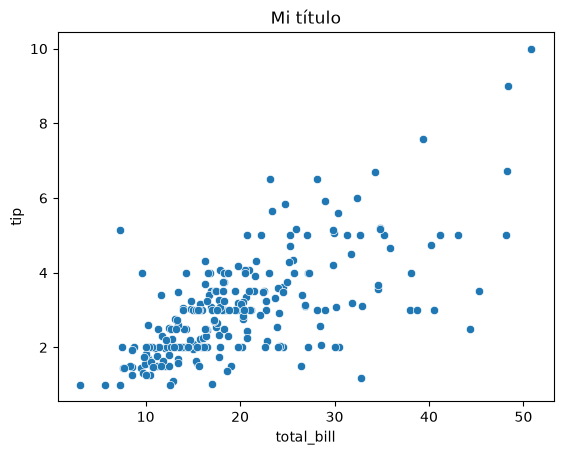

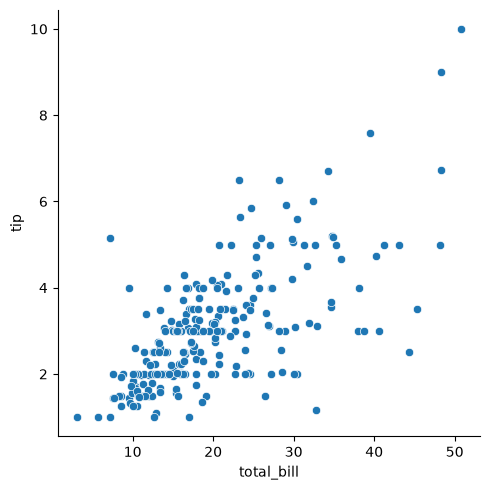

In [5]:
# DIFERENCIA CLAVE EN CÓDIGO:

# Axes-level (retorna un Axes)
ax = sns.scatterplot(data=tips, x='total_bill', y='tip')
ax.set_title('Mi título')  # Puedes usar métodos de Matplotlib

# Figure-level (retorna un FacetGrid)
g = sns.relplot(data=tips, x='total_bill', y='tip')
# g.figure.suptitle('Mi título')  # Así se modifica

### 1.3 Temas Globales con set_theme()
Configura el estilo de UNA VEZ y olvídate:

In [6]:
# La configuración MÁS COMPLETA en una línea
sns.set_theme(
    context='notebook',    # Escala: 'paper', 'notebook', 'talk', 'poster'
    style='whitegrid',     # Estilo: 'darkgrid', 'whitegrid', 'dark', 'white', 'ticks'
    palette='deep',        # Paleta: 'deep', 'muted', 'bright', 'pastel', 'dark', 'colorblind'
    font='sans-serif',
    font_scale=1.1,
    color_codes=True
)

# Alternativas comunes:
# sns.set_theme(style='whitegrid', context='talk')   # Para presentaciones
# sns.set_theme(style='darkgrid', palette='muted')   # Para análisis exploratorio
# sns.set_theme(style='ticks', context='paper')      # Para publicaciones académicas

# Resetear a valores por defecto de Matplotlib
# sns.set_theme()  # activa el theme por defecto de Seaborn

## 2. Gráficos de Relación (relplot / scatterplot / lineplot)
Para visualizar la relación entre dos variables numéricas.

### 2.1 Scatter Plot (Gráfico de Dispersión)

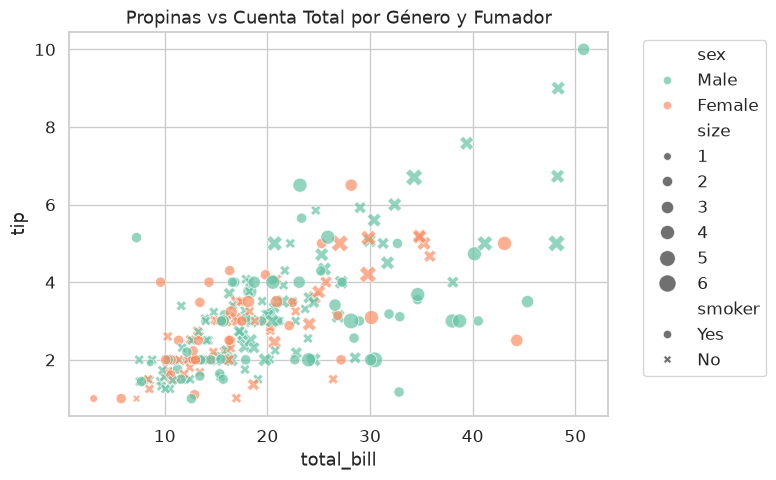

In [7]:
# --- Axes-level: scatterplot() ---
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=tips, 
    x='total_bill', 
    y='tip',
    hue='sex',           # Color por categoría
    style='smoker',      # Forma del marcador
    size='size',         # Tamaño del marcador
    sizes=(30, 150),     # Rango de tamaños
    alpha=0.7,           # Transparencia
    palette='Set2',      # Paleta de colores
    ax=ax
)
ax.set_title('Propinas vs Cuenta Total por Género y Fumador')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 2.2 Line Plot (Gráfico de Líneas)


/tmp/ipykernel_24843/954425941.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.lineplot(


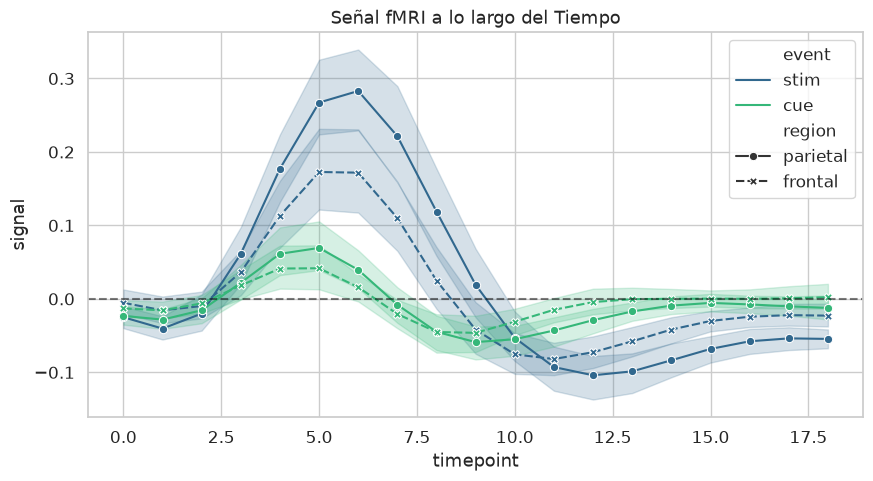

In [8]:
# --- Axes-level: lineplot() ---
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(
    data=fmri,
    x='timepoint',
    y='signal',
    hue='event',         # Color por evento
    style='region',      # Estilo de línea por región
    markers=True,        # Muestra marcadores en los puntos
    dashes=True,         # Líneas punteadas según estilo
    ci=95,               # Intervalo de confianza (o 'sd')
    palette='viridis',
    ax=ax
)
ax.set_title('Señal fMRI a lo largo del Tiempo')
ax.axhline(y=0, color='black', linestyle='--', alpha=0.5)
plt.show()

### 2.3 Figure-level: relplot() (Facetado Automático)


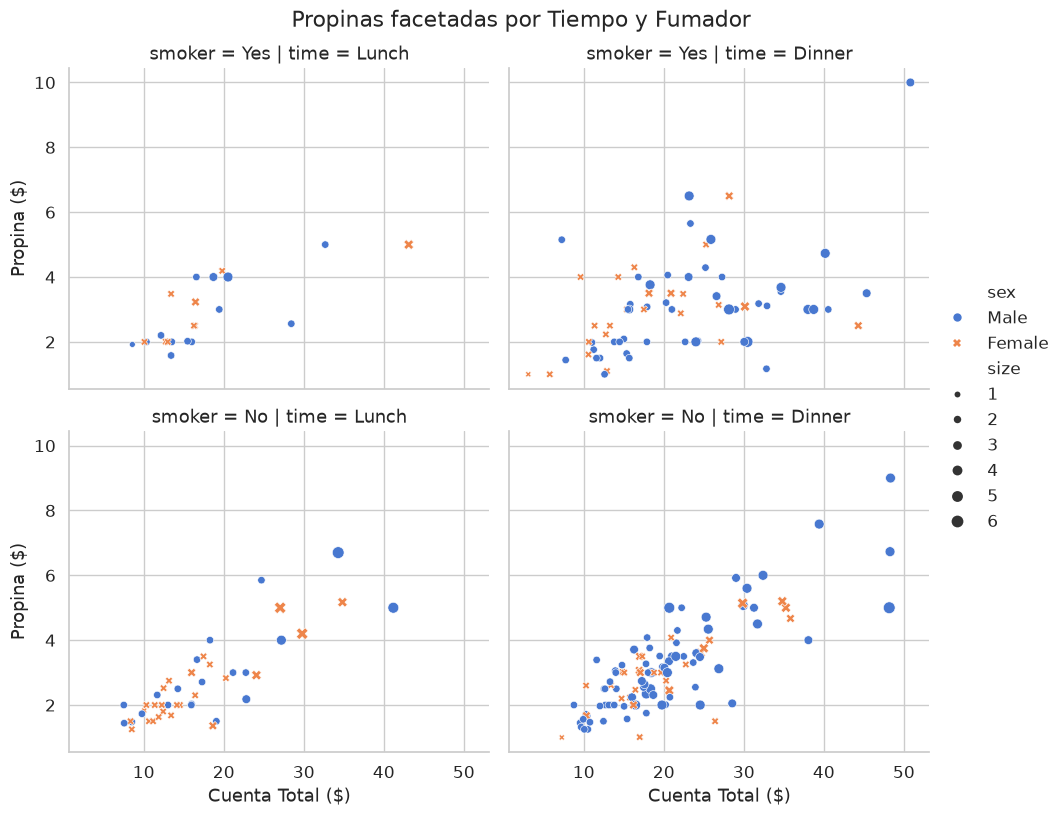

In [9]:
# --- Figure-level: relplot() ---
g = sns.relplot(
    data=tips,
    x='total_bill',
    y='tip',
    hue='sex',
    col='time',          # Faceta por columna (Dinner/Lunch)
    row='smoker',        # Faceta por fila (Yes/No)
    style='sex',
    size='size',
    palette='muted',
    height=4,
    aspect=1.2
)
g.figure.suptitle('Propinas facetadas por Tiempo y Fumador', y=1.02)
g.set_axis_labels('Cuenta Total ($)', 'Propina ($)')
plt.show()

## 3. Gráficos de Distribución
Para entender cómo se distribuyen una o más variables numéricas.

### 3.1 Histograma (histplot)

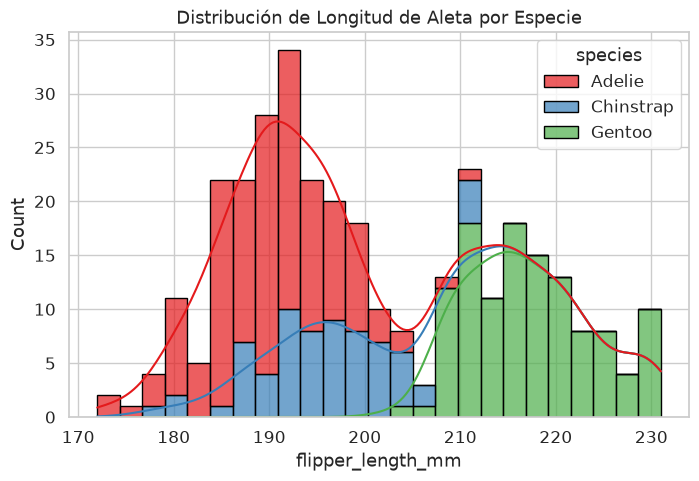

In [14]:
# --- Histograma básico ---
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(
    data=penguins,
    x='flipper_length_mm',
    hue='species',           # Color por especie
    multiple='stack',        # 'stack', 'dodge', 'fill', 'layer'
    bins=25,                 # Número de bins
    kde=True,                # Añade curva de densidad
    stat='count',            # 'count', 'density', 'probability', 'percent'
    palette='Set1',
    edgecolor='black',
    alpha=0.7,
    ax=ax
)
ax.set_title('Distribución de Longitud de Aleta por Especie')
plt.show()

### 3.2 KDE (Estimación de Densidad por Kernel) (kdeplot)


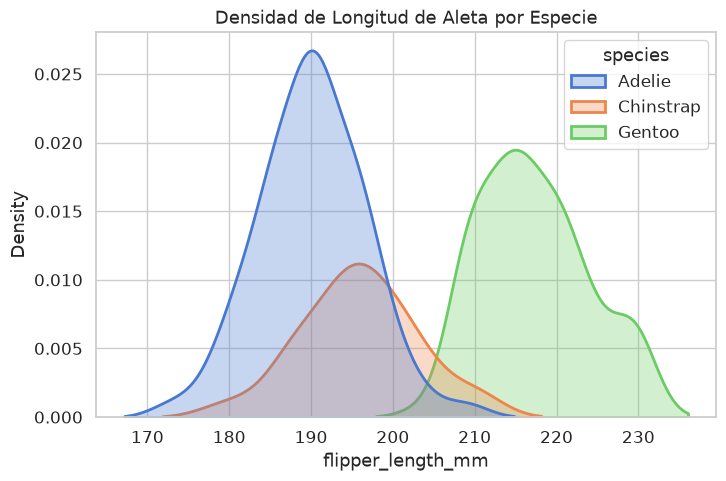

In [15]:
# --- KDE Plot ---
fig, ax = plt.subplots(figsize=(8, 5))
sns.kdeplot(
    data=penguins,
    x='flipper_length_mm',
    hue='species',
    multiple='layer',        # 'layer', 'stack', 'fill'
    fill=True,               # Rellena bajo la curva
    alpha=0.3,
    palette='muted',
    linewidth=2,
    cut=2,                   # Extiende más allá de los datos
    ax=ax
)
ax.set_title('Densidad de Longitud de Aleta por Especie')
plt.show()

### 3.3 ECDF (Función de Distribución Acumulada Empírica) (ecdfplot)


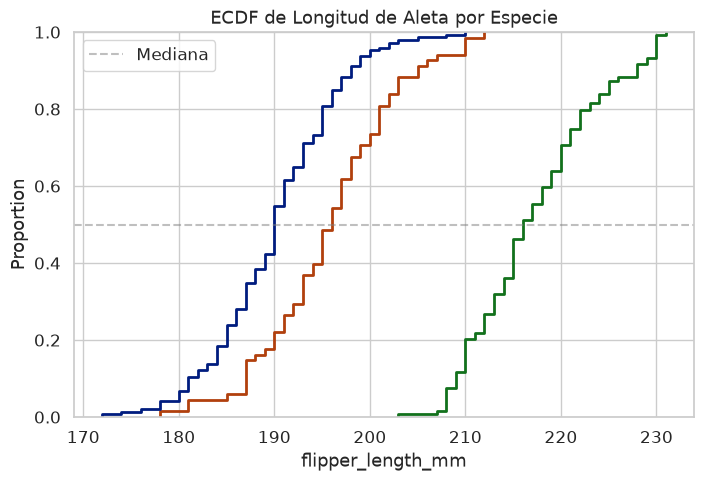

In [16]:
# --- ECDF Plot (MUY ÚTIL para comparar distribuciones) ---
fig, ax = plt.subplots(figsize=(8, 5))
sns.ecdfplot(
    data=penguins,
    x='flipper_length_mm',
    hue='species',
    palette='dark',
    linewidth=2,
    ax=ax
)
ax.set_title('ECDF de Longitud de Aleta por Especie')
ax.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='Mediana')
ax.legend()
plt.show()

### 3.4 Rug Plot (Marcas en el Eje) (rugplot)


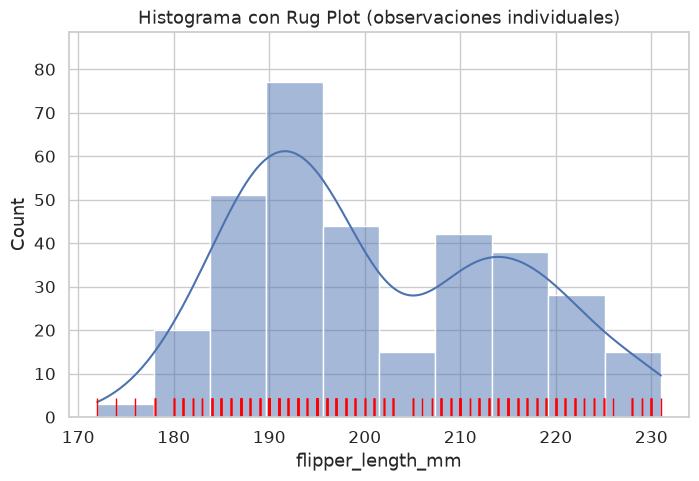

In [17]:
# --- Rug plot (muestra cada observación individual) ---
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=penguins, x='flipper_length_mm', kde=True, alpha=0.5, ax=ax)
sns.rugplot(data=penguins, x='flipper_length_mm', height=0.05, color='red', ax=ax)
ax.set_title('Histograma con Rug Plot (observaciones individuales)')
plt.show()

### 3.5 Figure-level: displot()


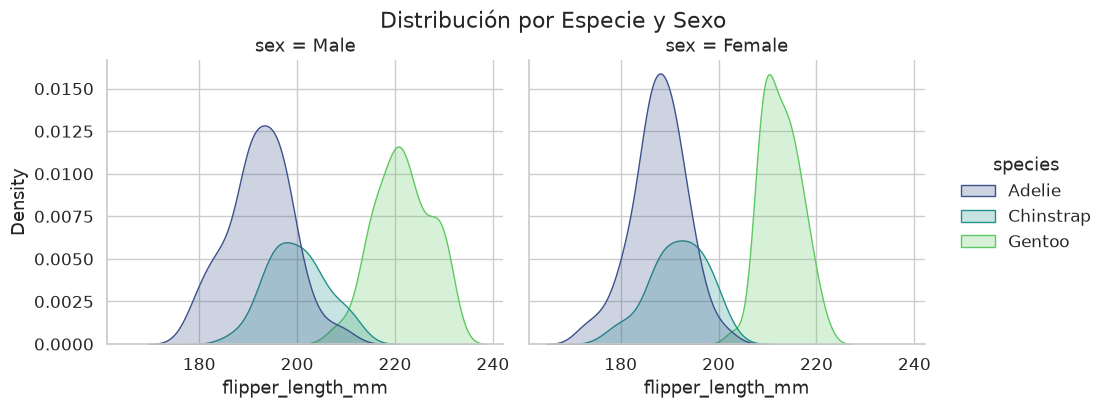

In [18]:
# --- Figure-level: displot() con facetado ---
g = sns.displot(
    data=penguins,
    x='flipper_length_mm',
    hue='species',
    col='sex',               # Faceta por sexo
    kind='kde',              # 'hist', 'kde', 'ecdf'
    fill=True,
    palette='viridis',
    height=4,
    aspect=1.2
)
g.figure.suptitle('Distribución por Especie y Sexo', y=1.02)
plt.show()

### 3.6 Jointplot (Distribución Conjunta)


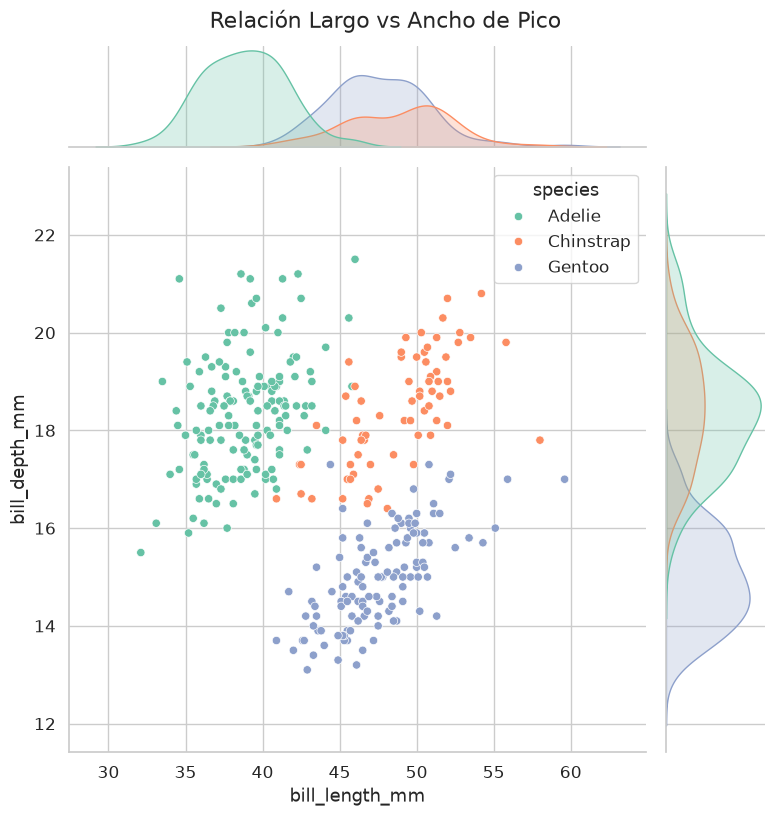

In [50]:
# --- Jointplot: scatter + histogramas marginales ---
g = sns.jointplot(
    data=penguins,
    x='bill_length_mm',
    y='bill_depth_mm',
    hue='species',
    kind='scatter',          # 'scatter', 'kde', 'hist', 'hex', 'reg'
    palette='Set2',
    height=8,
    # marginal_kws=dict(fill=True, alpha=0.5)  # Sin bins, solo ajustes de KDE

)
g.figure.suptitle('Relación Largo vs Ancho de Pico', y=1.02)
plt.show()

### 3.7 Pairplot (Matriz de Dispersión)


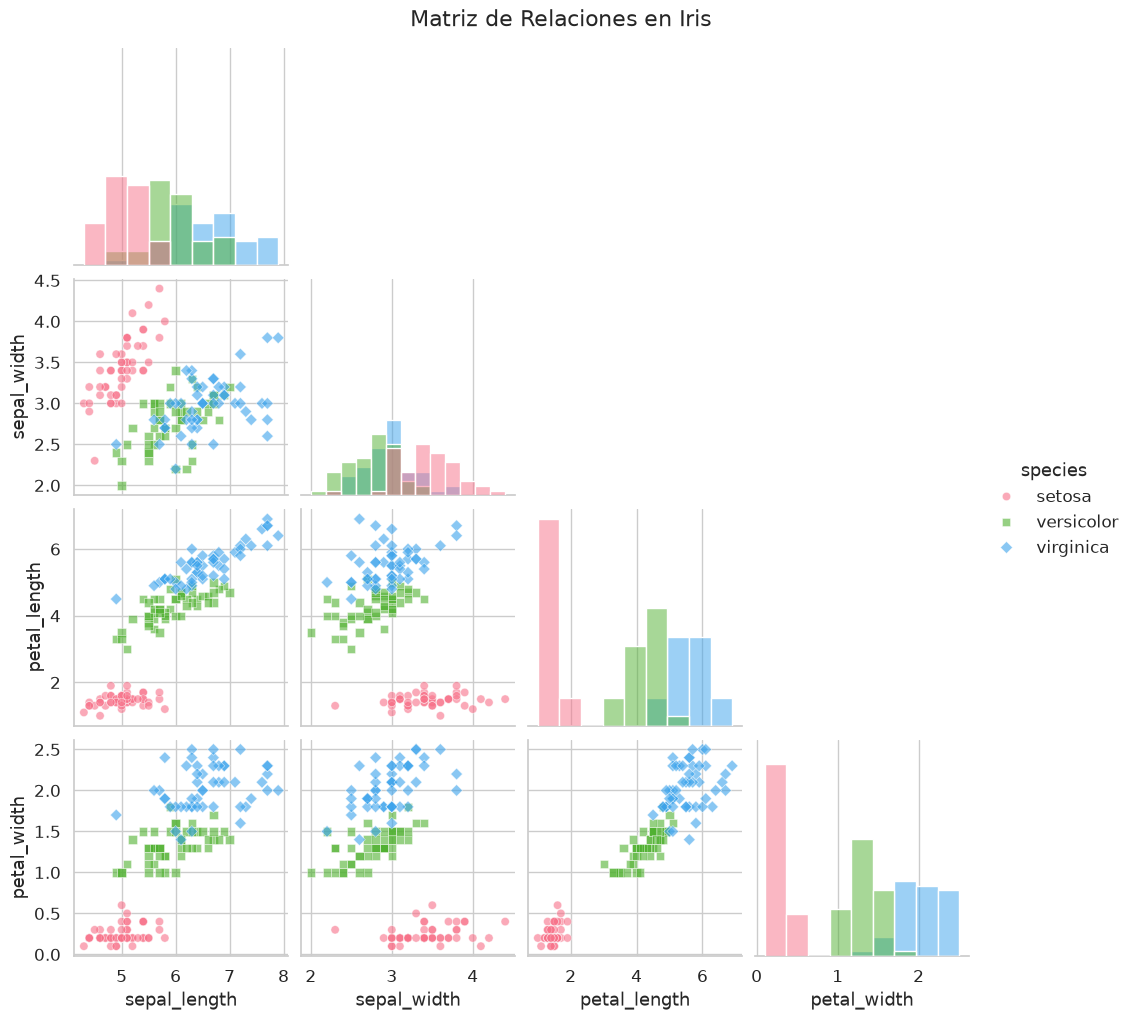

In [23]:
# --- Pairplot: TODAS las relaciones numéricas ---
g = sns.pairplot(
    data=iris,
    hue='species',
    palette='husl',
    diag_kind='hist',        # 'hist' o 'kde'
    kind='scatter',
    markers=['o', 's', 'D'],
    height=2.5,
    corner=True,             # Solo la mitad inferior (más limpio)
    plot_kws={'alpha': 0.6}
)
g.figure.suptitle('Matriz de Relaciones en Iris', y=1.02)
plt.show()

## 4. Gráficos Categóricos (catplot)
Para visualizar relaciones con variables categóricas. Seaborn los divide en tres grupos:

### 4.1 Observaciones Individuales: stripplot y swarmplot

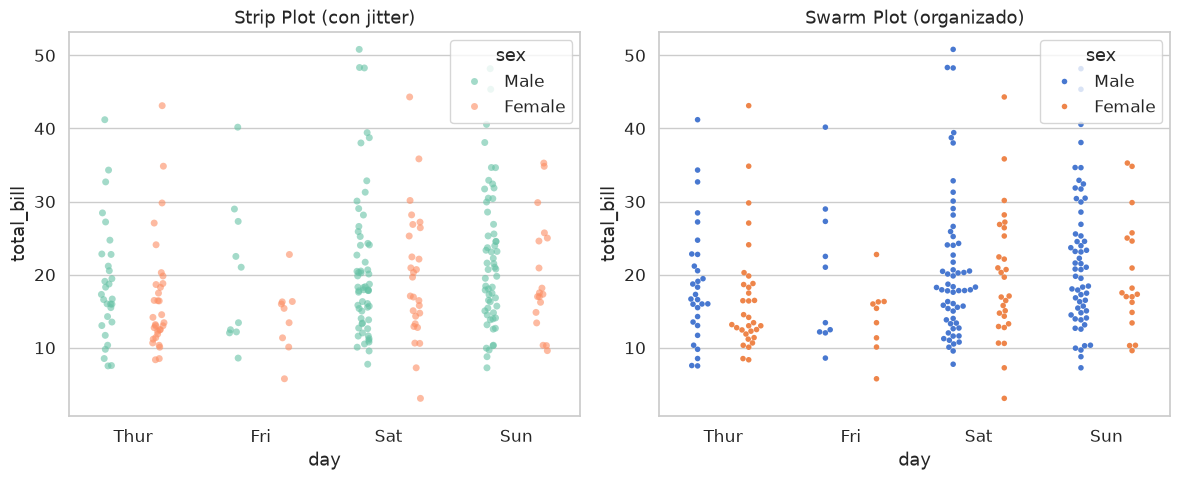

In [24]:
# --- Strip plot (puntos dispersos con jitter) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

sns.stripplot(
    data=tips, x='day', y='total_bill',
    hue='sex', dodge=True, jitter=True, alpha=0.6,
    palette='Set2', ax=ax1
)
ax1.set_title('Strip Plot (con jitter)')

# --- Swarm plot (puntos organizados para no solaparse) ---
sns.swarmplot(
    data=tips, x='day', y='total_bill',
    hue='sex', dodge=True, size=4,
    palette='muted', ax=ax2
)
ax2.set_title('Swarm Plot (organizado)')

plt.tight_layout()
plt.show()

### 4.2 Distribuciones Resumidas: boxplot, violinplot, boxenplot


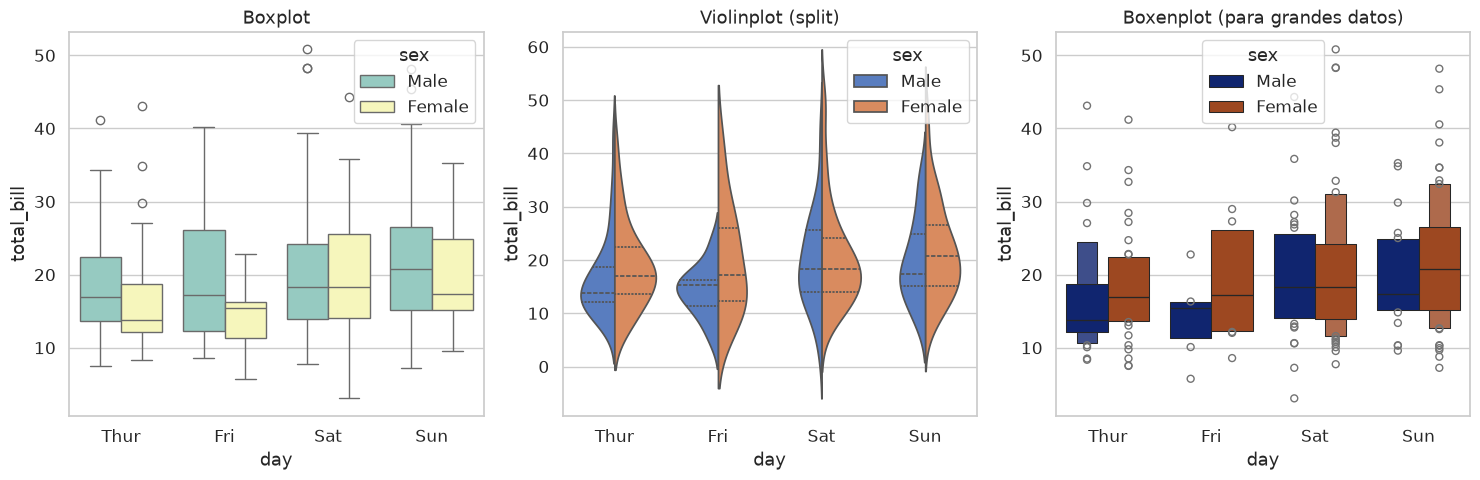

In [25]:
# --- Boxplot (cuartiles y outliers) ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(
    data=tips, x='day', y='total_bill',
    hue='sex', palette='Set3', ax=axes[0]
)
axes[0].set_title('Boxplot')

# --- Violinplot (boxplot + KDE) ---
sns.violinplot(
    data=tips, x='day', y='total_bill',
    hue='sex', split=True,  # Divide violín por categoría
    inner='quartile',       # 'box', 'quartile', 'point', 'stick'
    palette='muted', ax=axes[1]
)
axes[1].set_title('Violinplot (split)')

# --- Boxenplot (para grandes datasets - más eficiente) ---
sns.boxenplot(
    data=tips, x='day', y='total_bill',
    hue='sex', palette='dark', ax=axes[2]
)
axes[2].set_title('Boxenplot (para grandes datos)')

plt.tight_layout()
plt.show()

### 4.3 Estimaciones Estadísticas: barplot y pointplot


/tmp/ipykernel_24843/3343900434.py:4: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.barplot(


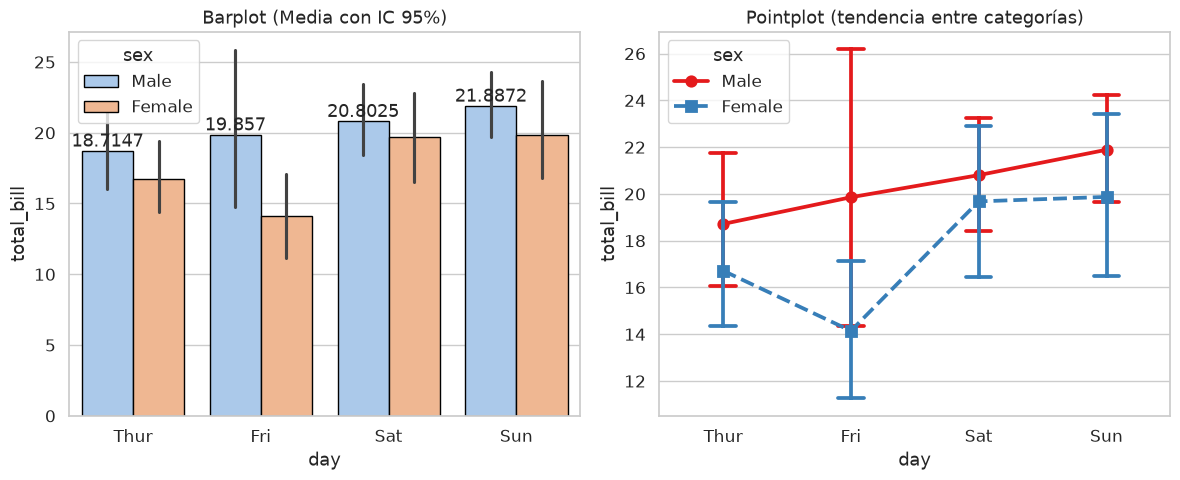

In [26]:
# --- Barplot (media + intervalo de confianza) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    data=tips, x='day', y='total_bill',
    hue='sex', estimator=np.mean,
    ci=95,                 # Intervalo de confianza
    palette='pastel',
    edgecolor='black',
    ax=ax1
)
ax1.set_title('Barplot (Media con IC 95%)')
ax1.bar_label(ax1.containers[0])  # Etiquetas encima

# --- Pointplot (media + IC, conectado por líneas) ---
sns.pointplot(
    data=tips, x='day', y='total_bill',
    hue='sex',
    markers=['o', 's'],
    linestyles=['-', '--'],
    capsize=0.2,           # Tamaño de las barras de error
    palette='Set1',
    ax=ax2
)
ax2.set_title('Pointplot (tendencia entre categorías)')

plt.tight_layout()
plt.show()

### 4.4 Countplot (Frecuencia de Categorías)


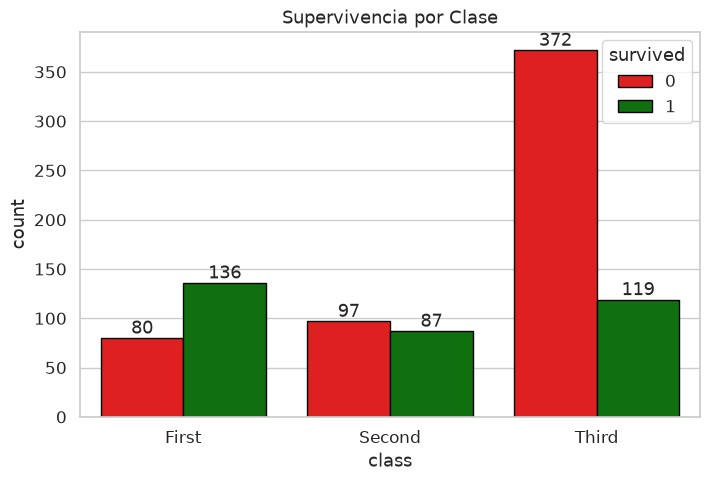

In [27]:
# --- Countplot (conteo de observaciones) ---
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(
    data=titanic,
    x='class',
    hue='survived',
    palette=['red', 'green'],
    edgecolor='black',
    ax=ax
)
ax.set_title('Supervivencia por Clase')
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.show()

### 4.5 Figure-level: catplot() (El Rey del Facetado)


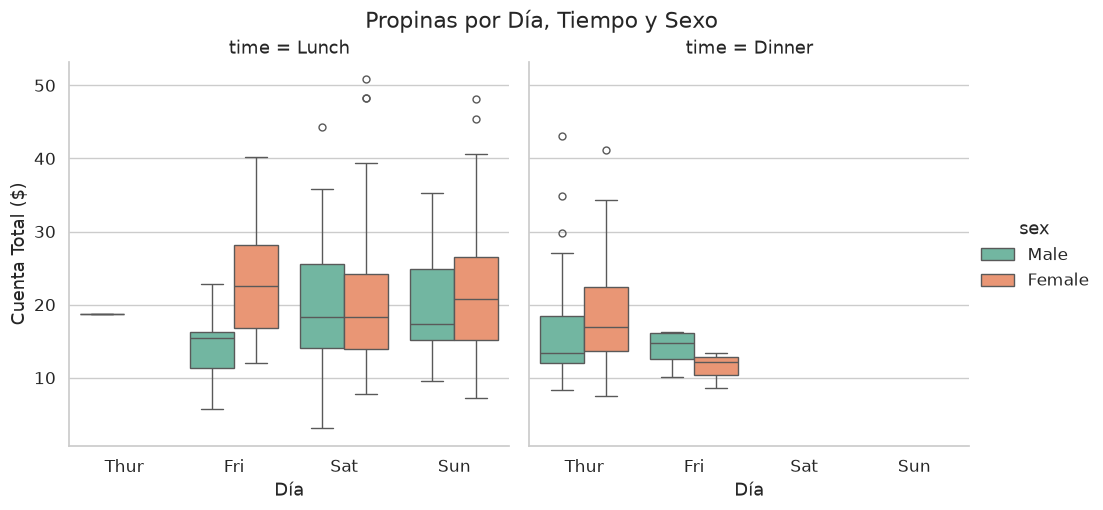

In [28]:
# --- catplot(): unifica TODOS los categorical plots ---
g = sns.catplot(
    data=tips,
    x='day',
    y='total_bill',
    hue='sex',
    col='time',            # Faceta por columna
    kind='box',            # 'strip', 'swarm', 'box', 'violin', 'boxen', 'point', 'bar', 'count'
    palette='Set2',
    height=5,
    aspect=1
)
g.figure.suptitle('Propinas por Día, Tiempo y Sexo', y=1.02)
g.set_axis_labels('Día', 'Cuenta Total ($)')
plt.show()

## 5. Gráficos de Matriz (heatmap y clustermap)
### 5.1 Heatmap (Mapa de Calor)

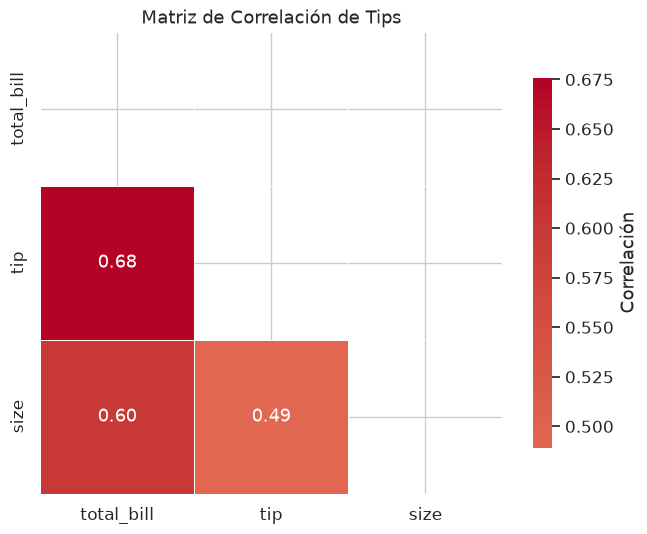

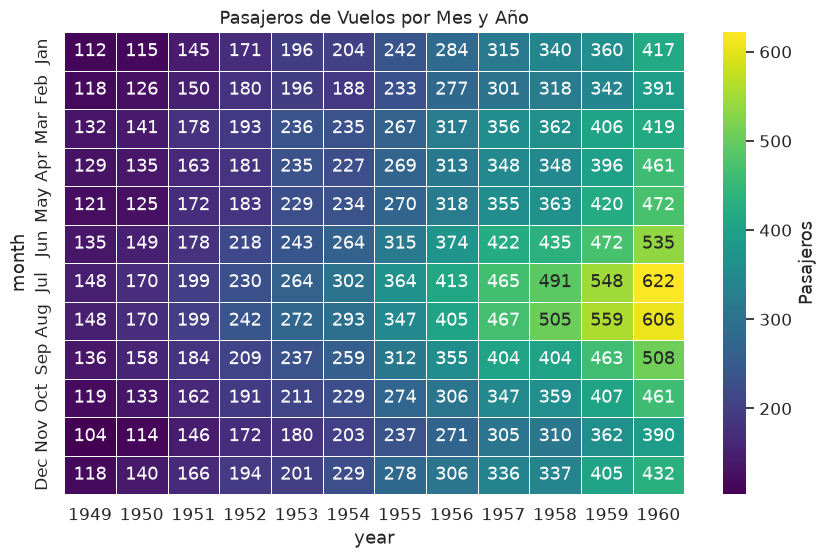

In [54]:
# --- Preparar datos para heatmap (matriz de correlación) ---
corr = tips.select_dtypes(include=[np.number]).corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,            # Muestra valores
    fmt='.2f',             # Formato de los números
    cmap='coolwarm',       # Colormap divergente
    center=0,              # Centro de la paleta
    square=True,           # Celdas cuadradas
    linewidths=0.5,
    cbar_kws={'shrink': 0.8, 'label': 'Correlación'},
    mask=np.triu(np.ones_like(corr, dtype=bool)),  # Oculta la mitad superior
    ax=ax
)
ax.set_title('Matriz de Correlación de Tips')
plt.show()

# --- Heatmap con datos de flights (pivot table) ---
flights_pivot = flights.pivot_table(index='month', columns='year', values='passengers')
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    flights_pivot,
    annot=True,
    fmt='.0f',                # ← Cambiado de 'd' a '.0f' (formato de entero sin decimales), fmt='d' solo funciona con números enteros
    cmap='viridis',
    linewidths=0.5,
    cbar_kws={'label': 'Pasajeros'},
    ax=ax
)
ax.set_title('Pasajeros de Vuelos por Mes y Año')
plt.show()

### 5.2 Clustermap (Heatmap con Clustering Jerárquico)


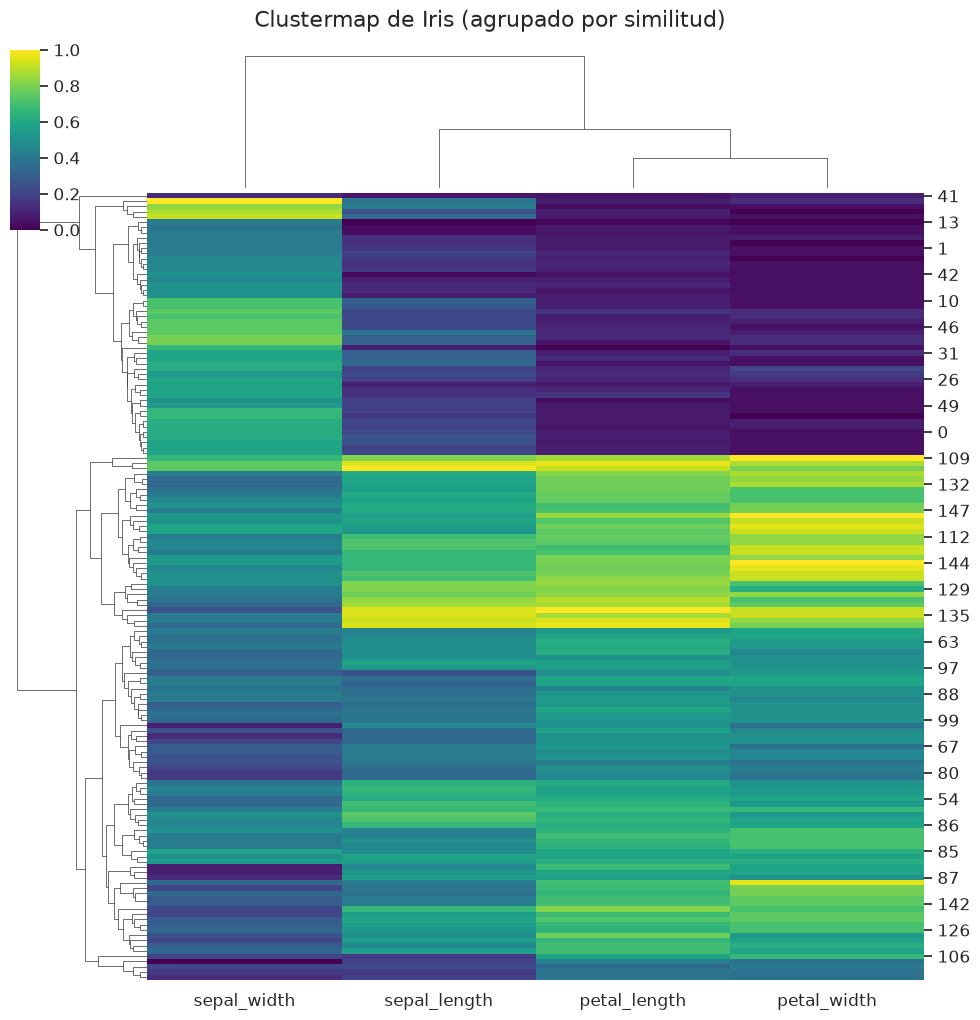

In [30]:
# --- Clustermap: agrupa filas y columnas por similitud ---
g = sns.clustermap(
    iris.drop('species', axis=1),
    cmap='viridis',
    standard_scale=1,      # Estandariza por columna
    method='average',      # Método de clustering
    metric='euclidean',    # Distancia
    figsize=(10, 10),
    dendrogram_ratio=0.15,
    cbar_pos=(0.02, 0.8, 0.03, 0.18)
)
g.figure.suptitle('Clustermap de Iris (agrupado por similitud)', y=1.02)
plt.show()

## 6. Gráficos de Regresión
Para visualizar relaciones y tendencias lineales.

### 6.1 regplot (Regresión en un Axes)

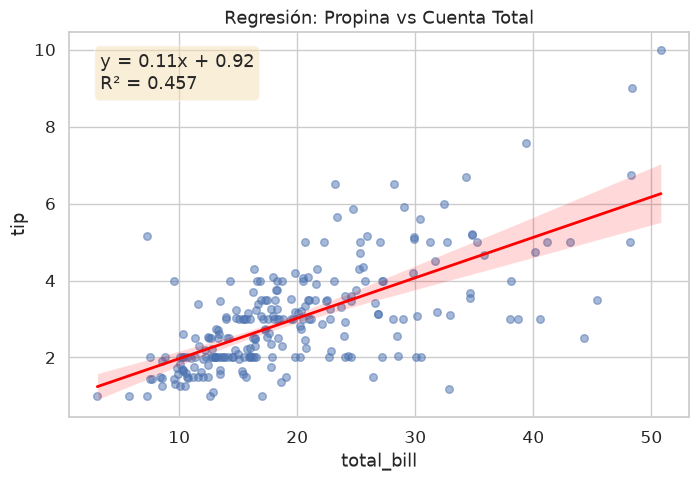

In [31]:
# --- regplot: scatter + línea de regresión + IC ---
fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(
    data=tips,
    x='total_bill',
    y='tip',
    scatter_kws={'alpha': 0.5, 's': 30},
    line_kws={'color': 'red', 'linewidth': 2},
    ci=95,
    ax=ax
)
ax.set_title('Regresión: Propina vs Cuenta Total')
# Mostrar ecuación de la regresión (opcional)
from scipy import stats
slope, intercept, r_value, p_value, std_err = stats.linregress(tips['total_bill'], tips['tip'])
ax.text(0.05, 0.95, f'y = {slope:.2f}x + {intercept:.2f}\nR² = {r_value**2:.3f}', 
        transform=ax.transAxes, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
plt.show()

### 6.2 lmplot (Regresión con Facetado)


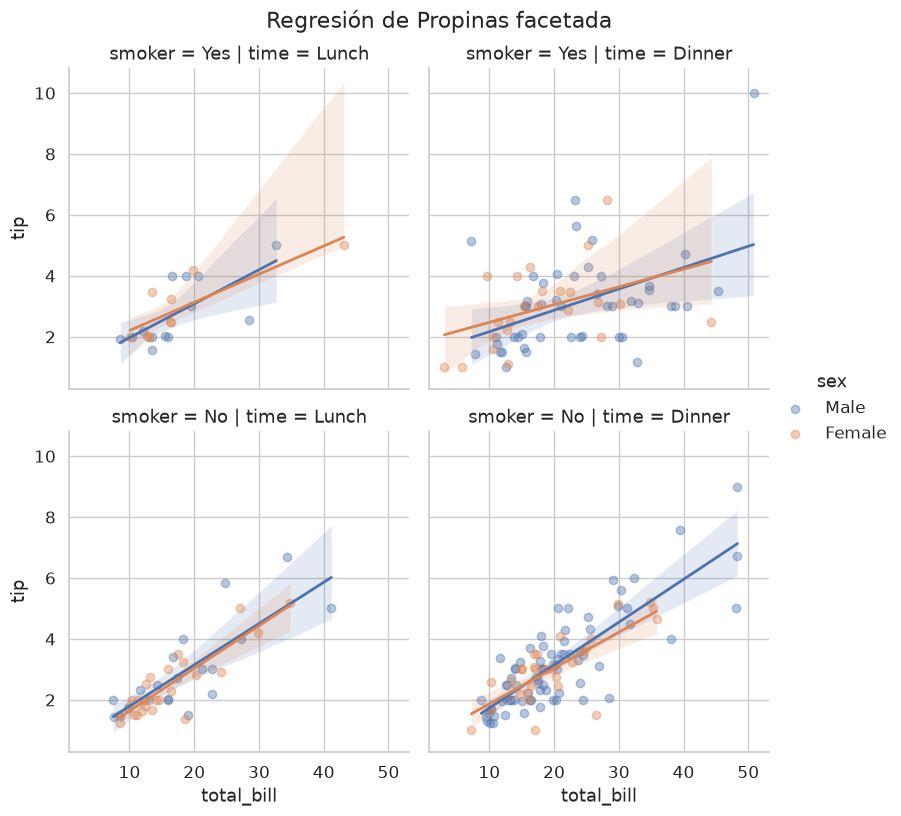

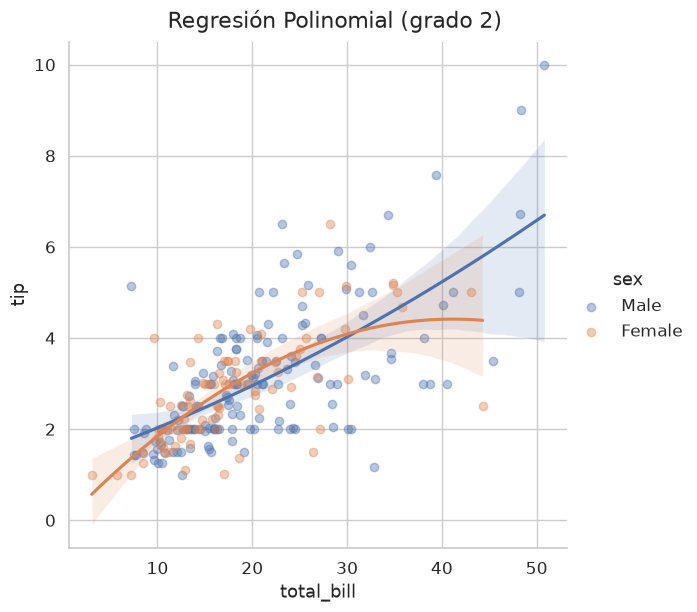

In [32]:
# --- lmplot: regresión + facetado automático ---
g = sns.lmplot(
    data=tips,
    x='total_bill',
    y='tip',
    hue='sex',
    col='time',
    row='smoker',
    height=4,
    aspect=1,
    scatter_kws={'alpha': 0.4},
    line_kws={'linewidth': 2}
)
g.figure.suptitle('Regresión de Propinas facetada', y=1.02)
plt.show()

# --- lmplot con regresión polinomial ---
g = sns.lmplot(
    data=tips,
    x='total_bill',
    y='tip',
    hue='sex',
    order=2,               # Regresión polinomial de grado 2
    scatter_kws={'alpha': 0.4},
    height=6
)
g.figure.suptitle('Regresión Polinomial (grado 2)', y=1.02)
plt.show()

--------

## 7. Paletas de Colores y Estilizado Avanzado
### 7.1 Paletas Cualitativas (para Categorías)

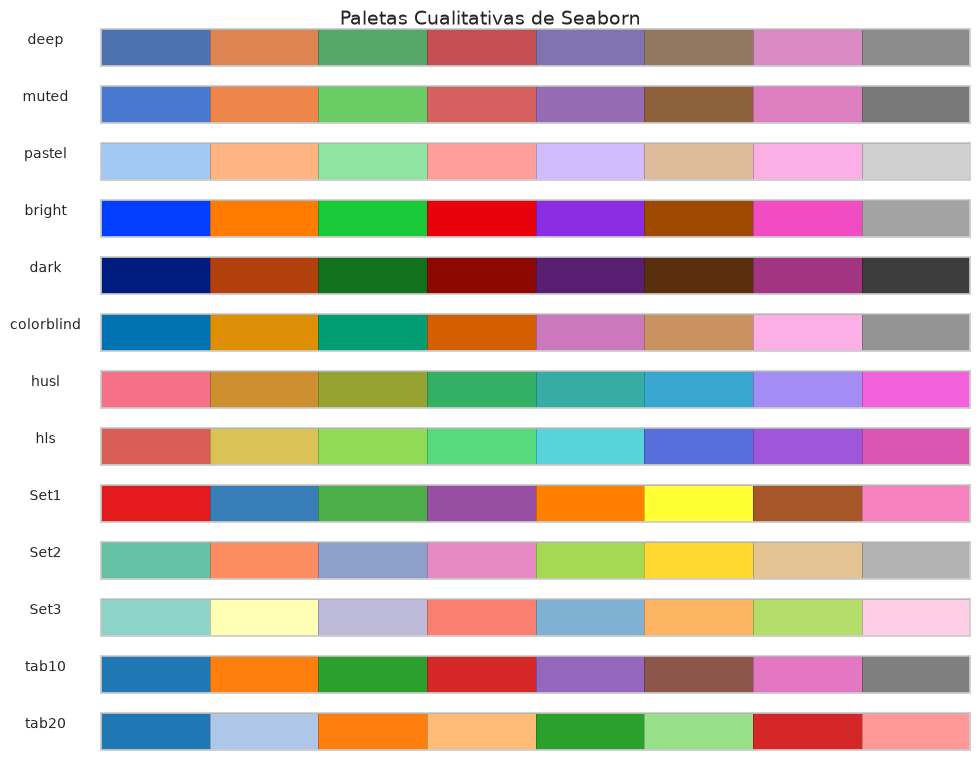

In [56]:
# Definir paletas cualitativas
paletas_cualitativas = ['deep', 'muted', 'pastel', 'bright', 'dark', 'colorblind', 
                        'husl', 'hls', 'Set1', 'Set2', 'Set3', 'tab10', 'tab20']

# Crear figura con subplots (una fila por paleta)
fig, axes = plt.subplots(len(paletas_cualitativas), 1, figsize=(10, 8))

for i, pal in enumerate(paletas_cualitativas):
    # Obtener los colores de la paleta
    colors = sns.color_palette(pal, 8)
    
    # Dibujar barras de colores horizontalmente
    # Creamos una imagen de 1x8 donde cada celda es un color
    ax = axes[i]
    # Usamos imshow para mostrar una fila de colores
    # Reshape a (1, n_colors, 3) para imshow
    color_array = np.array(colors).reshape(1, -1, 3)
    ax.imshow(color_array, aspect='auto', extent=[0, 8, 0, 1])
    ax.set_xlim(0, 8)
    ax.set_ylim(0, 1)
    ax.set_ylabel(pal, rotation=0, labelpad=40, fontsize=10)
    ax.set_xticks([])   # Ocultar marcas del eje X
    ax.set_yticks([])   # Ocultar marcas del eje Y
    # Opcional: añadir borde a cada celda
    for j in range(8):
        ax.axvline(x=j, color='black', linewidth=0.5, alpha=0.3)
        ax.axhline(y=0, color='black', linewidth=0.5, alpha=0.3)
        ax.axhline(y=1, color='black', linewidth=0.5, alpha=0.3)
    # Última línea vertical al final
    ax.axvline(x=8, color='black', linewidth=0.5, alpha=0.3)

plt.suptitle('Paletas Cualitativas de Seaborn', fontsize=14, y=0.95)
plt.tight_layout()
plt.show()

# Configurar paleta global (sigue funcionando)
sns.set_palette('colorblind')  # Ahora todos los gráficos usan esta paleta

### 7.2 Paletas Secuenciales y Divergentes


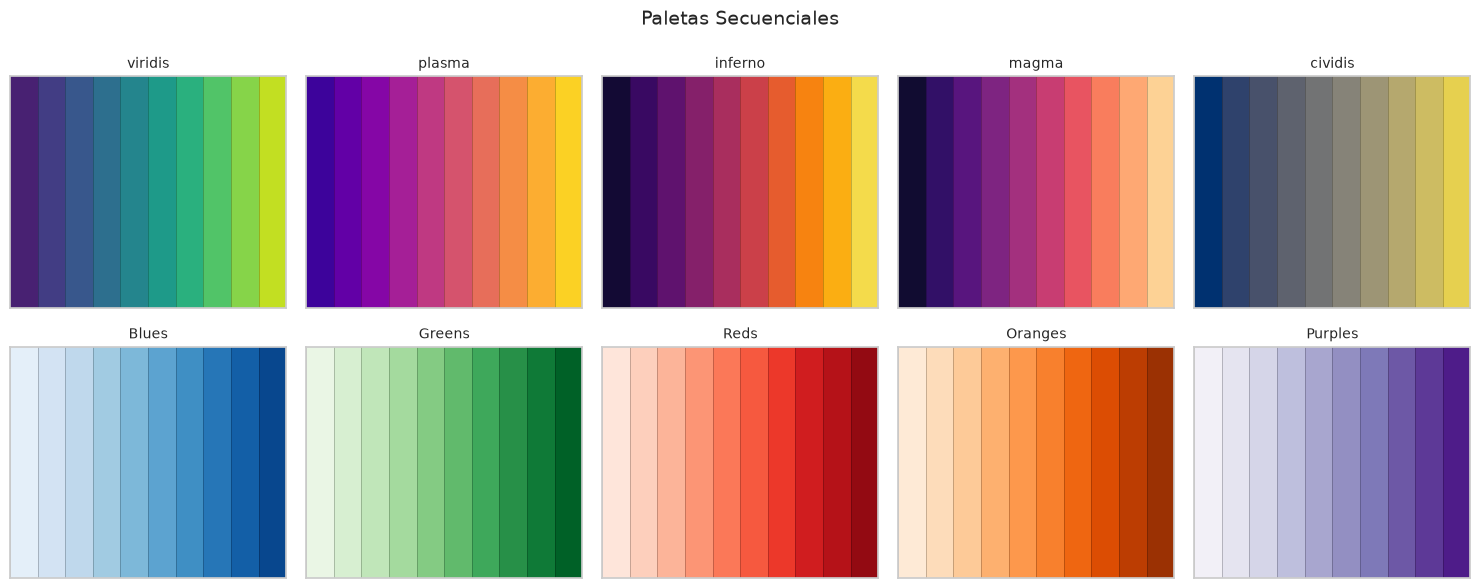

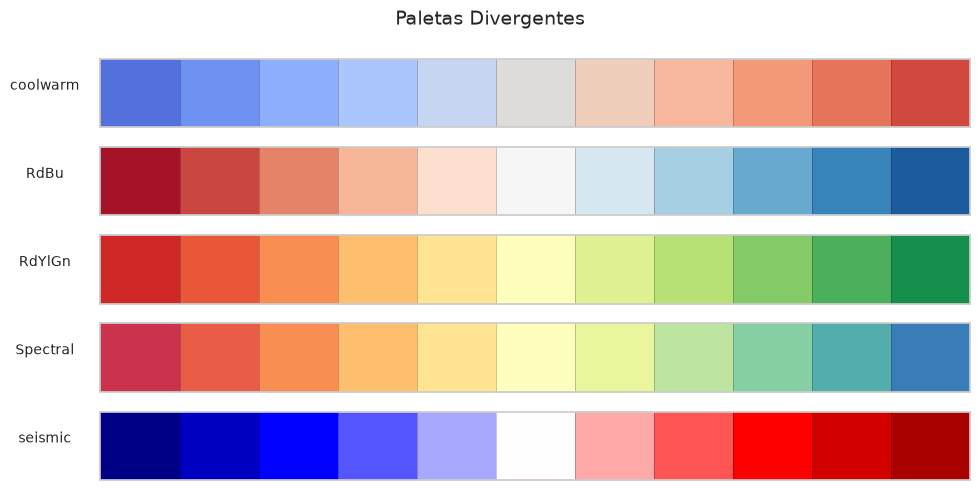

In [57]:
# --- Paletas SECUENCIALES (de claro a oscuro) ---
secuenciales = ['viridis', 'plasma', 'inferno', 'magma', 'cividis', 
                'Blues', 'Greens', 'Reds', 'Oranges', 'Purples']

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, pal in enumerate(secuenciales):
    # Obtener colores de la paleta
    colors = sns.color_palette(pal, 10)
    # Dibujar barra de colores con imshow
    ax = axes[i//5, i%5]
    color_array = np.array(colors).reshape(1, -1, 3)
    ax.imshow(color_array, aspect='auto', extent=[0, 10, 0, 1])
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 1)
    ax.set_title(pal, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    # Bordes entre celdas (opcional)
    for j in range(10):
        ax.axvline(x=j, color='black', linewidth=0.5, alpha=0.3)
    ax.axvline(x=10, color='black', linewidth=0.5, alpha=0.3)

plt.suptitle('Paletas Secuenciales', fontsize=14)
plt.tight_layout()
plt.show()

# --- Paletas DIVERGENTES (para datos con punto medio) ---
divergentes = ['coolwarm', 'RdBu', 'RdYlGn', 'Spectral', 'seismic']

fig, axes = plt.subplots(len(divergentes), 1, figsize=(10, 5))
for i, pal in enumerate(divergentes):
    # Obtener colores de la paleta (11 colores para incluir el centro)
    colors = sns.color_palette(pal, 11)
    ax = axes[i]
    color_array = np.array(colors).reshape(1, -1, 3)
    ax.imshow(color_array, aspect='auto', extent=[0, 11, 0, 1])
    ax.set_xlim(0, 11)
    ax.set_ylim(0, 1)
    ax.set_ylabel(pal, rotation=0, labelpad=40, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    # Bordes entre celdas
    for j in range(11):
        ax.axvline(x=j, color='black', linewidth=0.5, alpha=0.3)
    ax.axvline(x=11, color='black', linewidth=0.5, alpha=0.3)

plt.suptitle('Paletas Divergentes', fontsize=14)
plt.tight_layout()
plt.show()

### 7.3 Usar Colormaps en Gráficos


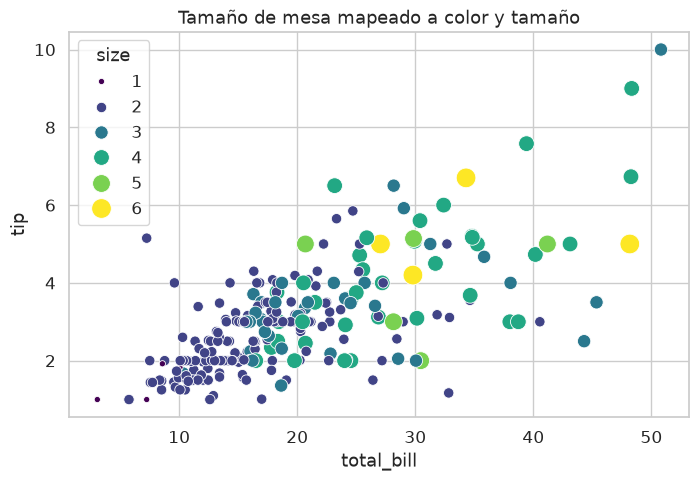

In [35]:
# --- Colormap continuo para scatter ---
fig, ax = plt.subplots(figsize=(8, 5))
scatter = sns.scatterplot(
    data=tips,
    x='total_bill',
    y='tip',
    hue='size',            # Variable numérica mapeada a color
    palette='viridis',     # Colormap continuo
    size='size',
    sizes=(20, 200)
)
ax.set_title('Tamaño de mesa mapeado a color y tamaño')
plt.show()

# --- Colormap para heatmap ---
# Se usa con el parámetro cmap='viridis' (o cualquier otro)

### 7.4 Contextos (Escalado de Elementos)


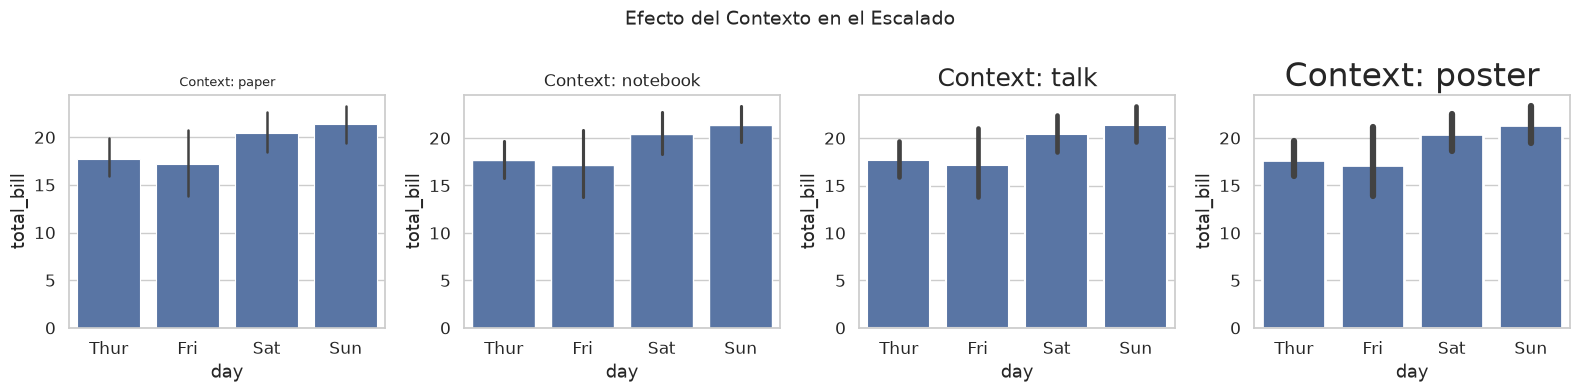

In [36]:
# --- ploting_context(): escala fuentes, líneas, etc ---
contextos = ['paper', 'notebook', 'talk', 'poster']

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i, ctx in enumerate(contextos):
    with sns.plotting_context(ctx):
        ax = axes[i]
        sns.barplot(data=tips, x='day', y='total_bill', ax=ax)
        ax.set_title(f'Context: {ctx}')
plt.suptitle('Efecto del Contexto en el Escalado', fontsize=14)
plt.tight_layout()
plt.show()

### 7.5 Estilos de Ejes (axes_style)


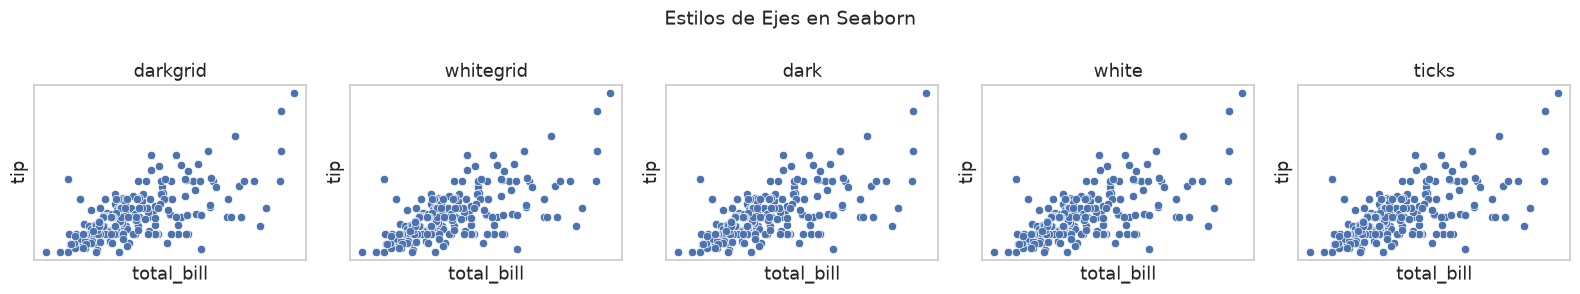

In [37]:
# --- axes_style(): cambia el fondo y las líneas ---
estilos = ['darkgrid', 'whitegrid', 'dark', 'white', 'ticks']

fig, axes = plt.subplots(1, 5, figsize=(16, 3))
for i, style in enumerate(estilos):
    with sns.axes_style(style):
        ax = axes[i]
        sns.scatterplot(data=tips, x='total_bill', y='tip', ax=ax)
        ax.set_title(style)
        ax.set_xticks([])
        ax.set_yticks([])
plt.suptitle('Estilos de Ejes en Seaborn', fontsize=14)
plt.tight_layout()
plt.show()

-------

## 8. Tuneo Fino y Personalización
### 8.1 Modificar Elementos de un FacetGrid (relplot, catplot, displot)

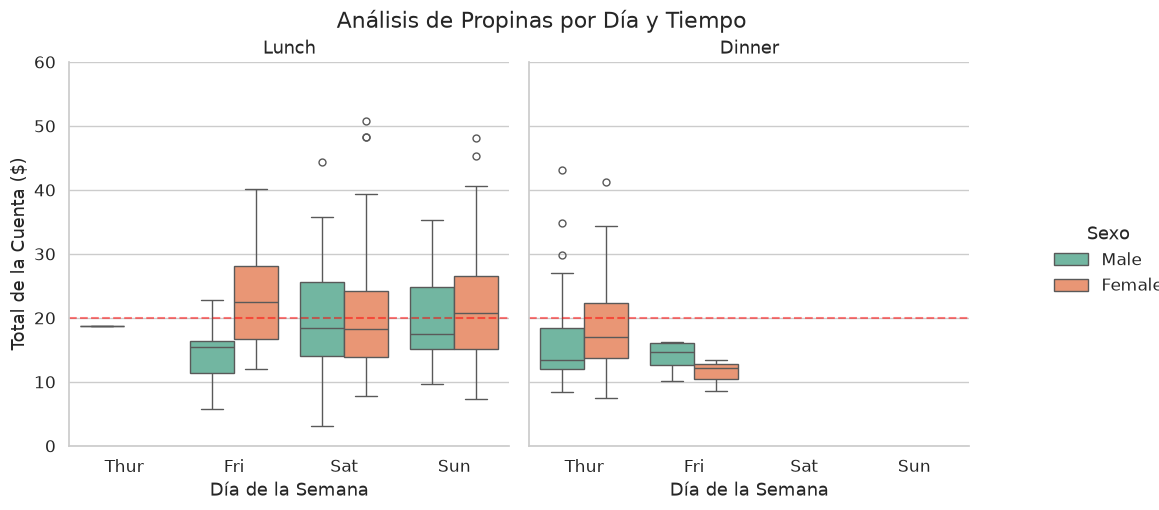

In [38]:
# --- Personalización de Figure-level functions ---
g = sns.catplot(
    data=tips,
    x='day',
    y='total_bill',
    hue='sex',
    col='time',
    kind='box',
    palette='Set2',
    height=5,
    aspect=1
)

# 1. Cambiar título general
g.figure.suptitle('Análisis de Propinas por Día y Tiempo', fontsize=16, y=1.02)

# 2. Cambiar etiquetas de ejes
g.set_axis_labels('Día de la Semana', 'Total de la Cuenta ($)')

# 3. Cambiar etiquetas de los subgráficos
g.set_titles('{col_name}')  # {col_name} o {row_name}

# 4. Ajustar límites de ejes
g.set(ylim=(0, 60))

# 5. Añadir una línea horizontal en todos los subplots
for ax in g.axes.flat:
    ax.axhline(y=20, color='red', linestyle='--', alpha=0.5)

# 6. Mover la leyenda
g.legend.set_title('Sexo')
g.legend.set_bbox_to_anchor((1.05, 0.5))

plt.show()

### 8.2 Combinar Seaborn con Matplotlib (Lo Mejor de Ambos Mundos)


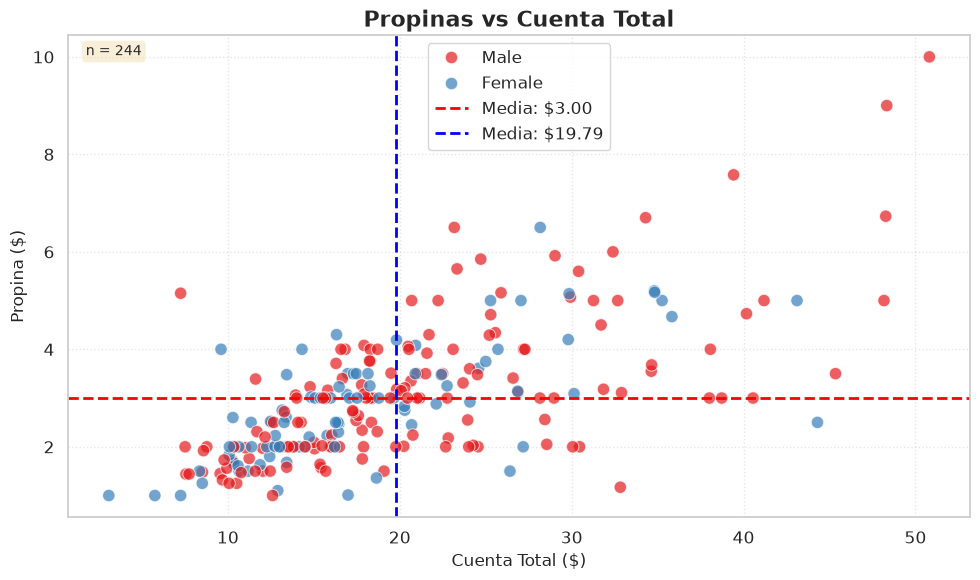

In [39]:
# --- Usar un Axes de Seaborn y luego modificarlo con Matplotlib ---
fig, ax = plt.subplots(figsize=(10, 6))

# 1. Dibujar con Seaborn
sns.scatterplot(data=tips, x='total_bill', y='tip', hue='sex', 
                palette='Set1', s=80, alpha=0.7, ax=ax)

# 2. Personalizar con Matplotlib
ax.set_title('Propinas vs Cuenta Total', fontsize=16, fontweight='bold')
ax.set_xlabel('Cuenta Total ($)', fontsize=12)
ax.set_ylabel('Propina ($)', fontsize=12)
ax.grid(True, linestyle=':', alpha=0.5)
ax.axhline(y=tips['tip'].mean(), color='red', linestyle='--', 
           linewidth=2, label=f'Media: ${tips["tip"].mean():.2f}')
ax.axvline(x=tips['total_bill'].mean(), color='blue', linestyle='--',
           linewidth=2, label=f'Media: ${tips["total_bill"].mean():.2f}')

# 3. Añadir texto personalizado
ax.text(0.02, 0.98, f'n = {len(tips)}', transform=ax.transAxes,
        verticalalignment='top', fontsize=10, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

ax.legend()
plt.tight_layout()
plt.show()

### 8.3 Anotaciones y Texto en Seaborn


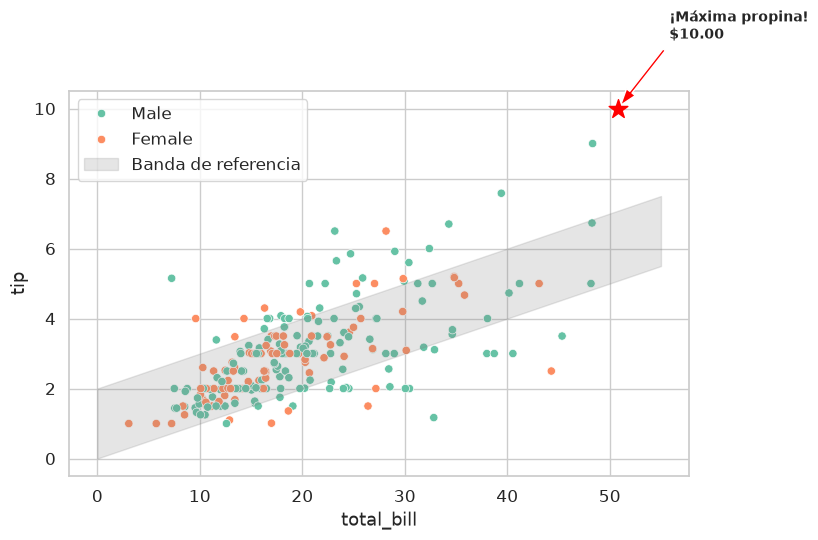

In [ ]:
# --- Añadir anotaciones a un gráfico de Seaborn ---
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=tips, x='total_bill', y='tip', hue='sex', palette='Set2', ax=ax)

# Encontrar el punto con la propina más alta
max_tip = tips.loc[tips['tip'].idxmax()]

ax.scatter(max_tip['total_bill'], max_tip['tip'], s=200, color='red', marker='*', zorder=10)

ax.annotate(f'¡Máxima propina!\n${max_tip["tip"]:.2f}', 
            xy=(max_tip['total_bill'], max_tip['tip']),
            xytext=(max_tip['total_bill'] + 5, max_tip['tip'] + 2),
            arrowprops=dict(facecolor='red', shrink=0.05, width=2, headwidth=8),
            fontsize=10, fontweight='bold')

# Añadir banda de confianza (ejemplo)
x_vals = np.linspace(0, 55, 100)
y_vals = 0.1 * x_vals + 1  # Línea de referencia
ax.fill_between(x_vals, y_vals - 1, y_vals + 1, alpha=0.2, color='gray', label='Banda de referencia')

ax.legend()
plt.show()

## 9. Resumen: ¿Qué gráfico usar para qué?

| **Propósito** | **Tipo de Variable** | **Axes-level** | **Figure-level** | **Parámetro `kind`** |
| :--- | :--- | :--- | :--- | :--- |
| **Relación** | 2 Numéricas | `scatterplot` | `relplot` | `kind='scatter'` |
| **Tendencia** | 2 Numéricas (ordenadas) | `lineplot` | `relplot` | `kind='line'` |
| **Distribución** | 1 Numérica | `histplot` / `kdeplot` / `ecdfplot` | `displot` | `kind='hist'/'kde'/'ecdf'` |
| **Distribución Conjunta** | 2 Numéricas | `jointplot` | - | - |
| **Matriz de Distribuciones** | Múltiples Numéricas | `pairplot` | - | - |
| **Categórica (puntos)** | 1 Cat + 1 Num | `stripplot` / `swarmplot` | `catplot` | `kind='strip'/'swarm'` |
| **Categórica (distribución)** | 1 Cat + 1 Num | `boxplot` / `violinplot` / `boxenplot` | `catplot` | `kind='box'/'violin'/'boxen'` |
| **Categórica (estimación)** | 1 Cat + 1 Num | `barplot` / `pointplot` | `catplot` | `kind='bar'/'point'` |
| **Frecuencia Categórica** | 1 Cat | `countplot` | `catplot` | `kind='count'` |
| **Matriz de Correlación** | Múltiples Numéricas | `heatmap` | - | - |
| **Clustering** | Múltiples Numéricas | `clustermap` | - | - |
| **Regresión** | 2 Numéricas | `regplot` | `lmplot` | - |

---

## 10. Buenas Prácticas y Checklist Final

1. **Configura el tema global** al inicio del notebook con `sns.set_theme()`.
2. **Elige la paleta adecuada**:
   - Categorías → Cualitativas (`'deep'`, `'muted'`, `'colorblind'`)
   - Datos secuenciales → `'viridis'`, `'Blues'`
   - Datos con punto medio → Divergentes (`'coolwarm'`, `'RdBu'`)
   - **Prioriza accesibilidad**: usa `'colorblind'`
3. **Distingue entre axes-level y figure-level**:
   - Si necesitas control fino con Matplotlib → axes-level (`scatterplot`, `boxplot`)
   - Si necesitas facetado automático → figure-level (`relplot`, `catplot`, `displot`)
4. **Aprovecha los parámetros semánticos**: `hue`, `size`, `style` para añadir dimensiones.
5. **Documenta tus gráficos**: títulos claros, ejes etiquetados, leyendas con sentido.
6. **Ajusta el tamaño**: usa `height` y `aspect` en figure-level, o `figsize` en axes-level.
7. **No sobrecargues**: máximo 3-4 variables por gráfico (hue + size + style + facetas).
8. **Para grandes datasets**:
   - Usa `boxenplot` en lugar de `boxplot`
   - Usa `kind='hex'` en `jointplot`
   - Reduce transparencia (`alpha=0.3`) o muestra una muestra representativa
9. **Para publicaciones**: usa `context='paper'` y `style='ticks'`.
10. **Exporta en alta calidad**: `g.figure.savefig('plot.png', dpi=300, bbox_inches='tight')`

---

## 11. Ejemplo Final: Dashboard de Análisis Exploratorio

/tmp/ipykernel_24843/913354607.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=tips, x='day', y='total_bill', palette='Set2', ax=ax2)
/tmp/ipykernel_24843/913354607.py:49: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


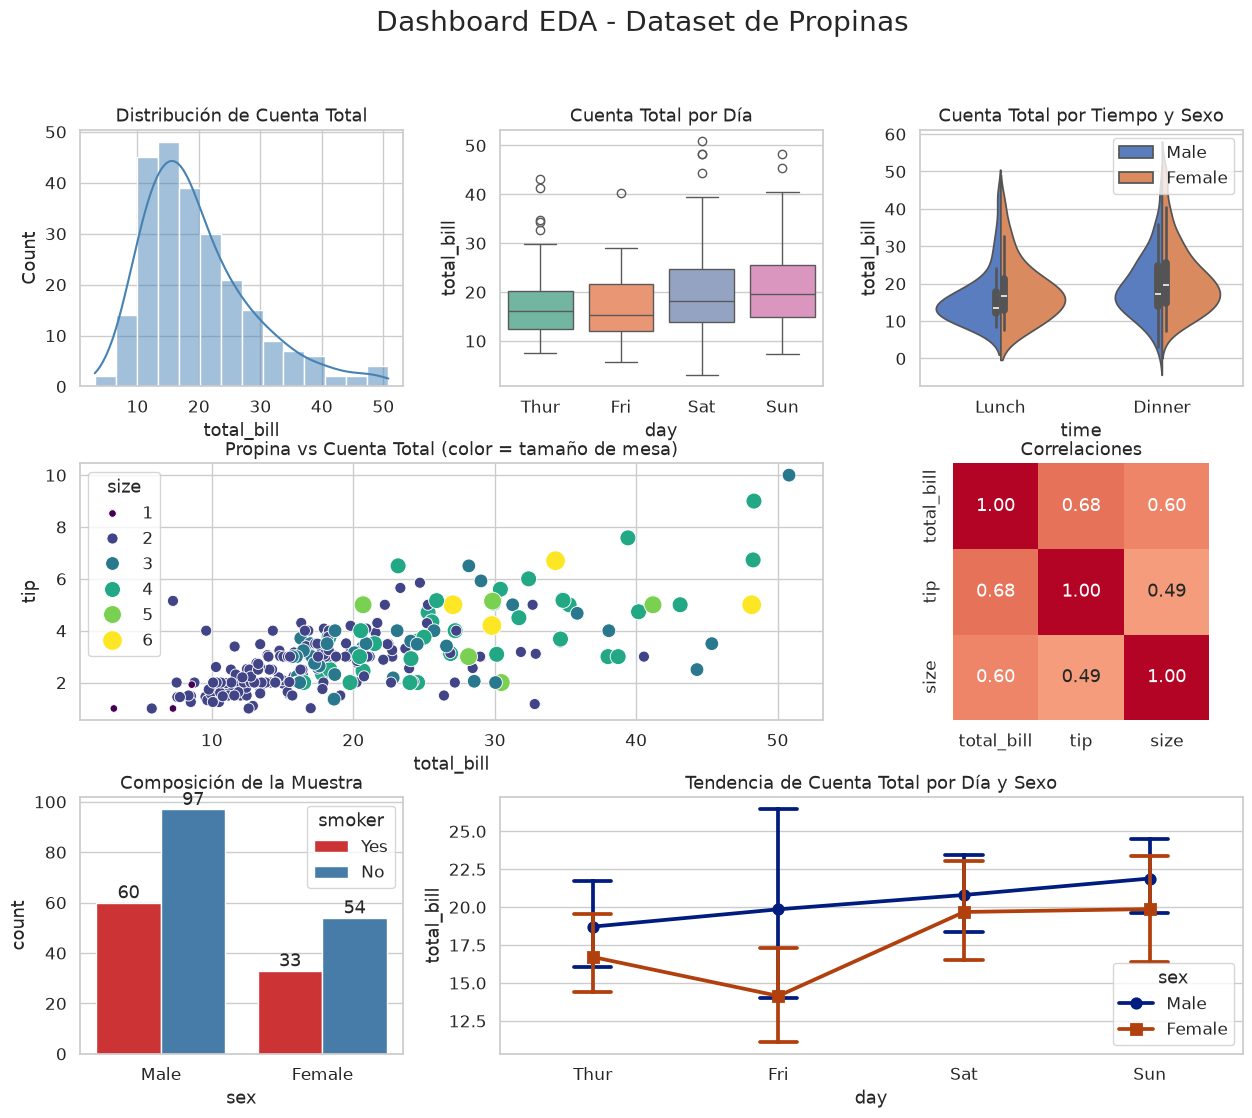

In [58]:
# --- Un dashboard EDA completo con Seaborn ---
fig = plt.figure(figsize=(15, 12))
gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)

# 1. Distribución de variable objetivo
ax1 = fig.add_subplot(gs[0, 0])
sns.histplot(data=tips, x='total_bill', kde=True, color='steelblue', ax=ax1)
ax1.set_title('Distribución de Cuenta Total')

# 2. Boxplot por categoría
ax2 = fig.add_subplot(gs[0, 1])
sns.boxplot(data=tips, x='day', y='total_bill', palette='Set2', ax=ax2)
ax2.set_title('Cuenta Total por Día')

# 3. Relación con variable categórica
ax3 = fig.add_subplot(gs[0, 2])
sns.violinplot(data=tips, x='time', y='total_bill', hue='sex', split=True, 
               palette='muted', ax=ax3)
ax3.set_title('Cuenta Total por Tiempo y Sexo')
ax3.legend(loc='upper right')

# 4. Scatter plot con hue
ax4 = fig.add_subplot(gs[1, :2])
sns.scatterplot(data=tips, x='total_bill', y='tip', hue='size', 
                size='size', sizes=(30, 200), palette='viridis', ax=ax4)
ax4.set_title('Propina vs Cuenta Total (color = tamaño de mesa)')

# 5. Heatmap de correlación
ax5 = fig.add_subplot(gs[1, 2])
corr = tips.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
            square=True, cbar=False, ax=ax5)
ax5.set_title('Correlaciones')

# 6. Countplot
ax6 = fig.add_subplot(gs[2, 0])
sns.countplot(data=tips, x='sex', hue='smoker', palette='Set1', ax=ax6)
ax6.set_title('Composición de la Muestra')
ax6.bar_label(ax6.containers[0])
ax6.bar_label(ax6.containers[1])

# 7. Pointplot de tendencias
ax7 = fig.add_subplot(gs[2, 1:])
sns.pointplot(data=tips, x='day', y='total_bill', hue='sex', 
              markers=['o', 's'], capsize=0.2, palette='dark', ax=ax7)
ax7.set_title('Tendencia de Cuenta Total por Día y Sexo')

plt.suptitle('Dashboard EDA - Dataset de Propinas', fontsize=20, y=0.98)
plt.tight_layout()
plt.show()